In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
pankrzysiu_cifar10_python_path = kagglehub.dataset_download('pankrzysiu/cifar10-python')

print('Data source import complete.')


Imports

In [ ]:
import time
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import datasets, layers, models
from tensorflow.keras.applications import EfficientNetB0
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# Set random seeds for reproducibility
tf.random.set_seed(42)
np.random.seed(42)

load dataset

In [ ]:
import os
import pickle
import numpy as np


cifar_dir = None
for root, dirs, files in os.walk('/kaggle/input'):
    if 'data_batch_1' in files:
        cifar_dir = root
        break

def load_batch(file_path):
    with open(file_path, 'rb') as f:
        batch = pickle.load(f, encoding='bytes')
    images = batch[b'data'].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
    labels = np.array(batch[b'labels']).reshape(-1, 1)
    return images, labels

train_images_list, train_labels_list = [], []
for i in range(1, 6):
    imgs, lbls = load_batch(os.path.join(cifar_dir, f'data_batch_{i}'))
    train_images_list.append(imgs)
    train_labels_list.append(lbls)

train_images = np.concatenate(train_images_list, axis=0)
train_labels = np.concatenate(train_labels_list, axis=0)


test_images, test_labels = load_batch(os.path.join(cifar_dir, 'test_batch'))

CLASS_NAMES = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

print(f"Loaded instantly from {cifar_dir}!")
print(f"Train shape: {train_images.shape}, Test shape: {test_images.shape}")

Loaded instantly from /kaggle/input/datasets/pankrzysiu/cifar10-python/cifar-10-batches-py!
Train shape: (50000, 32, 32, 3), Test shape: (10000, 32, 32, 3)


CNN model

In [ ]:
inputs = keras.Input(shape=(32, 32, 3))
x = layers.Rescaling(1./255)(inputs)  # Normalize pixel values to [0, 1]

# Block 1
x = layers.Conv2D(32, (3, 3), activation='relu')(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Dropout(0.25)(x)

# Block 2
x = layers.Conv2D(64, (3, 3), activation='relu')(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Dropout(0.25)(x)

# Block 3
x = layers.Conv2D(64, (3, 3), activation='relu')(x)
x = layers.Dropout(0.25)(x)

# Flatten and Dense Brain
x = layers.Flatten()(x)
x = layers.Dense(64, activation='relu')(x)
x = layers.Dropout(0.5)(x)

# Final output
outputs = layers.Dense(10, activation='softmax')(x)

cnn_model = keras.Model(inputs=inputs, outputs=outputs, name="cifar_dropout_model")
cnn_model.summary()

cnn_model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

start_time = time.time()
history_cnn = cnn_model.fit(
    train_images, train_labels,
    epochs=40,
    batch_size=64,
    validation_data=(test_images, test_labels)
)
cnn_time = time.time() - start_time

cnn_model.save('/kaggle/working/cifar_custom_cnn.keras')
print(f"\nCustom CNN Training Time: {cnn_time:.1f}s")

Model: "cifar_dropout_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 21s 15ms/step - accuracy: 0.3238 - loss: 1.8159 - val_accuracy: 0.4751 - val_loss: 1.4327
Epoch 2/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.4670 - loss: 1.4708 - val_accuracy: 0.5573 - val_loss: 1.2630
Epoch 3/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.5222 - loss: 1.3371 - val_accuracy: 0.5965 - val_loss: 1.1443
Epoch 4/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.5557 - loss: 1.2587 - val_accuracy: 0.6219 - val_loss: 1.0636
Epoch 5/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.5755 - loss: 1.2051 - val_accuracy: 0.6533 - val_loss: 1.0158
Epoch 6/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.5962 - loss: 1.1509 - val_accuracy: 0.6525 - val_loss: 0.9961
Epoch 7/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6124 - loss: 1.1088 - val_accuracy: 0.6753 - val_loss: 0.9396
Epoch 8/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6218 - loss: 1.0815 - val_accuracy: 

In [ ]:
# Load EfficientNetB0 pretrained on ImageNet
base_model = EfficientNetB0(
    include_top=False,
    weights='imagenet',
    input_shape=(96, 96, 3)
)
base_model.trainable = False  # Freeze pretrained layers

eff_inputs = keras.Input(shape=(32, 32, 3))
# Upscale 32x32 -> 96x96 so EfficientNet preserves spatial features
x = layers.Resizing(96, 96)(eff_inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
eff_outputs = layers.Dense(10, activation='softmax')(x)

eff_model = keras.Model(inputs=eff_inputs, outputs=eff_outputs, name="cifar_efficientnet_b0")
eff_model.summary()

eff_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

early_stop = keras.callbacks.EarlyStopping(
    patience=3,
    restore_best_weights=True,
    monitor='val_accuracy'
)

start_time = time.time()
history_eff = eff_model.fit(
    train_images, train_labels,
    epochs=15,
    batch_size=64,
    validation_data=(test_images, test_labels),
    callbacks=[early_stop]
)
eff_time = time.time() - start_time

eff_model.save('/kaggle/working/cifar_efficientnet_b0.keras')
print(f"\nEfficientNetB0 Training Time: {eff_time:.1f}s")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "cifar_efficientnet_b0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 3, 3, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,062,381 (15.50 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Epoch 1/15


E0000 00:00:1795557298.195373     176 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795557298.362813     176 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795557299.645840     176 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795557299.824771     176 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


781/782 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7133 - loss: 0.9079

E0000 00:00:1795557325.517495     175 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795557325.683035     175 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795557326.180178     175 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795557326.358135     175 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


782/782 ━━━━━━━━━━━━━━━━━━━━ 64s 47ms/step - accuracy: 0.7858 - loss: 0.6662 - val_accuracy: 0.8394 - val_loss: 0.4714
Epoch 2/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.8331 - loss: 0.4979 - val_accuracy: 0.8539 - val_loss: 0.4405
Epoch 3/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.8421 - loss: 0.4742 - val_accuracy: 0.8561 - val_loss: 0.4296
Epoch 4/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.8431 - loss: 0.4630 - val_accuracy: 0.8574 - val_loss: 0.4208
Epoch 5/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.8485 - loss: 0.4540 - val_accuracy: 0.8590 - val_loss: 0.4181
Epoch 6/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.8461 - loss: 0.4492 - val_accuracy: 0.8590 - val_loss: 0.4159
Epoch 7/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.8515 - loss: 0.4425 - val_accuracy: 0.8594 - val_loss: 0.4133
Epoch 8/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.8506 - loss: 0.4418 - val_accurac

E0000 00:00:1795557599.040874     176 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795557599.221619     176 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795557600.643750     176 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795557600.799321     176 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


================ MODEL COMPARISON ================
Custom CNN     -> Test Loss: 0.7117 | Test Acc: 75.73% | Params: 122,570 | Time: 152.9s
EfficientNetB0 -> Test Loss: 0.4128 | Test Acc: 86.11% | Params: 4,062,381 | Time: 230.6s


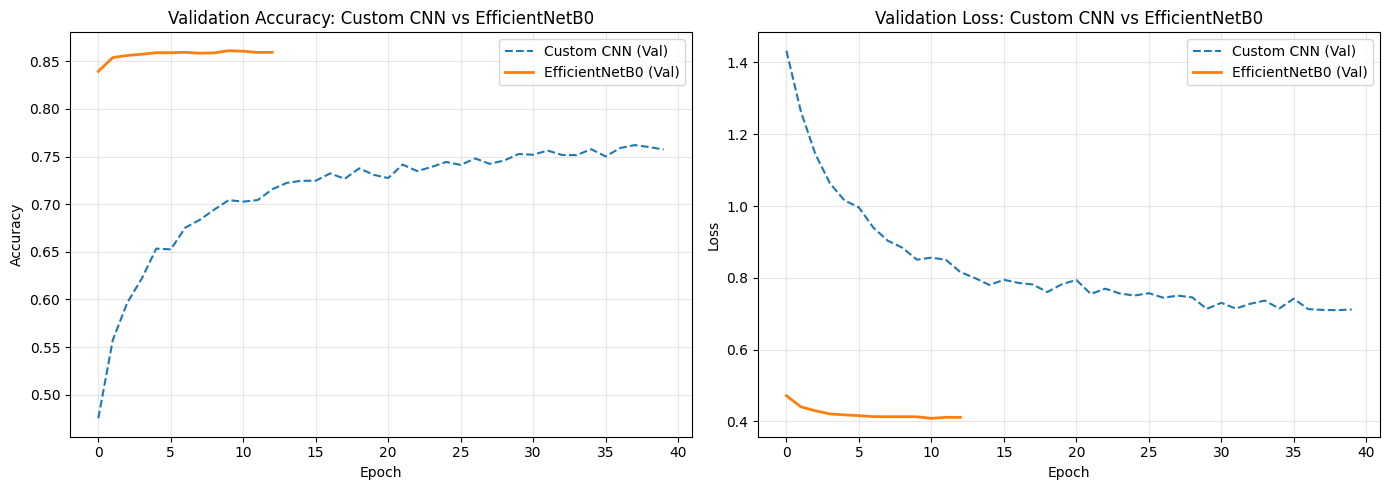


--- Custom CNN Classification Report ---
              precision    recall  f1-score   support

    airplane     0.7559    0.8020    0.7783      1000
  automobile     0.9316    0.8440    0.8856      1000
        bird     0.7842    0.5050    0.6144      1000
         cat     0.6120    0.5710    0.5908      1000
        deer     0.6562    0.7770    0.7115      1000
         dog     0.6935    0.6470    0.6694      1000
        frog     0.7815    0.8440    0.8115      1000
       horse     0.7917    0.8060    0.7988      1000
        ship     0.7858    0.8990    0.8386      1000
       truck     0.8004    0.8780    0.8374      1000

    accuracy                         0.7573     10000
   macro avg     0.7593    0.7573    0.7536     10000
weighted avg     0.7593    0.7573    0.7536     10000


--- EfficientNetB0 Classification Report ---
              precision    recall  f1-score   support

    airplane     0.8671    0.8610    0.8640      1000
  automobile     0.9313    0.9220    0.9266 

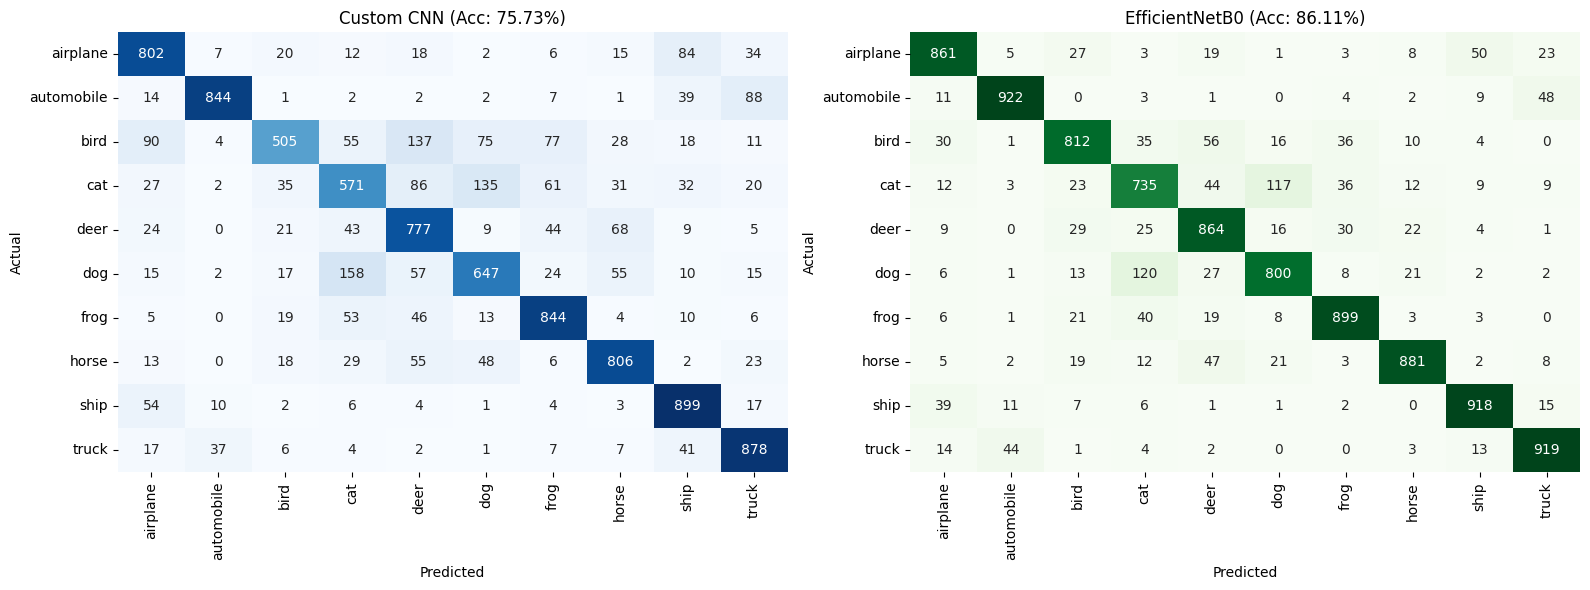

In [ ]:
# 1. Evaluate both models on the test set
cnn_score = cnn_model.evaluate(test_images, test_labels, verbose=0)
eff_score = eff_model.evaluate(test_images, test_labels, verbose=0)

print("================ MODEL COMPARISON ================")
print(f"Custom CNN     -> Test Loss: {cnn_score[0]:.4f} | Test Acc: {cnn_score[1]*100:.2f}% | Params: {cnn_model.count_params():,} | Time: {cnn_time:.1f}s")
print(f"EfficientNetB0 -> Test Loss: {eff_score[0]:.4f} | Test Acc: {eff_score[1]*100:.2f}% | Params: {eff_model.count_params():,} | Time: {eff_time:.1f}s")

# 2. Plot Training & Validation Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_cnn.history['val_accuracy'], label='Custom CNN (Val)', linestyle='--')
axes[0].plot(history_eff.history['val_accuracy'], label='EfficientNetB0 (Val)', linewidth=2)
axes[0].set_title('Validation Accuracy: Custom CNN vs EfficientNetB0')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history_cnn.history['val_loss'], label='Custom CNN (Val)', linestyle='--')
axes[1].plot(history_eff.history['val_loss'], label='EfficientNetB0 (Val)', linewidth=2)
axes[1].set_title('Validation Loss: Custom CNN vs EfficientNetB0')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/kaggle/working/comparison_curves.png', dpi=300)
plt.show()

# 3. Classification Reports & Confusion Matrices
y_true = test_labels.flatten()
y_pred_cnn = np.argmax(cnn_model.predict(test_images, verbose=0), axis=1)
y_pred_eff = np.argmax(eff_model.predict(test_images, verbose=0), axis=1)

print("\n--- Custom CNN Classification Report ---")
print(classification_report(y_true, y_pred_cnn, target_names=CLASS_NAMES, digits=4))

print("\n--- EfficientNetB0 Classification Report ---")
print(classification_report(y_true, y_pred_eff, target_names=CLASS_NAMES, digits=4))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(confusion_matrix(y_true, y_pred_cnn), annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=False, ax=axes[0])
axes[0].set_title(f'Custom CNN (Acc: {cnn_score[1]*100:.2f}%)')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

sns.heatmap(confusion_matrix(y_true, y_pred_eff), annot=True, fmt='d', cmap='Greens',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=False, ax=axes[1])
axes[1].set_title(f'EfficientNetB0 (Acc: {eff_score[1]*100:.2f}%)')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.savefig('/kaggle/working/confusion_matrices.png', dpi=300)
plt.show()